# Étude de l'évolution du coût de l'or

L'or est un symbole de richesse depuis des millénaires. Avec l'avènement des différents moyens d'échange, notamment la monnaie fiduciaire, il est resté jusqu'au début des années 1970 un élément central du système monétaire international et de la convertibilité des devises.

Malgré la transformation du système monétaire international et les évolutions liées à la dédollarisation, l'or reste aujourd'hui un actif largement utilisé comme **valeur refuge** et comme instrument de couverture contre certains risques financiers, notamment en période de crise et de forte inflation.

Comprendre les dynamiques qui influencent le prix de l'or constitue donc un enjeu important pour les différents acteurs des marchés financiers. À travers une étude comparative, nous analyserons l'évolution du cours de l'or et sa performance relativement à d'autres actifs et indicateurs économiques.

## Points clés

- 📈 Évolution du cours de l'or
- 💰 Évolution des rendements annuels de l'or par rapport au CAC 40
- 📊 Évolution du coût de l'or par rapport au CAC 40
- 📉 Évolution du coût de l'or par rapport à l'inflation


Install & import librairies

In [ ]:
#!pip install yfinance
#!pip install matplotlib

In [52]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [53]:
import sys
print(sys.executable)

c:\Users\Alfred\Desktop\MMMEF\Python for optimization in finance\Gold_vs_inflation\.venv\Scripts\python.exe


# Download historical gold data

In [54]:

tickers = ["GC=F"]
data_gold = yf.download(tickers,  start="1970-01-01", end="2026-01-01",interval="1d", auto_adjust=True)

[*********************100%***********************]  1 of 1 completed


In [55]:
data_gold

Price,Close,High,Low,Open,Volume
Ticker,GC=F,GC=F,GC=F,GC=F,GC=F
Date,,,,,
2000-08-30,273.899994,273.899994,273.899994,273.899994,0
2000-08-31,278.299988,278.299988,274.799988,274.799988,0
2000-09-01,277.000000,277.000000,277.000000,277.000000,0
2000-09-05,275.799988,275.799988,275.799988,275.799988,2
2000-09-06,274.200012,274.200012,274.200012,274.200012,0
...,...,...,...,...,...
2025-12-24,4502.799805,4555.100098,4474.299805,4516.700195,151576
2025-12-26,4552.700195,4584.000000,4518.000000,4523.500000,181246


Use close prices for analysis

In [56]:
gold_price = data_gold['Close']

In [57]:
search_na = gold_price.isna().sum()

In [58]:
print(f"Number of missing values in gold price data: {search_na}")

Number of missing values in gold price data: Ticker
GC=F    0
dtype: int64


# Evolution du cours de l'or

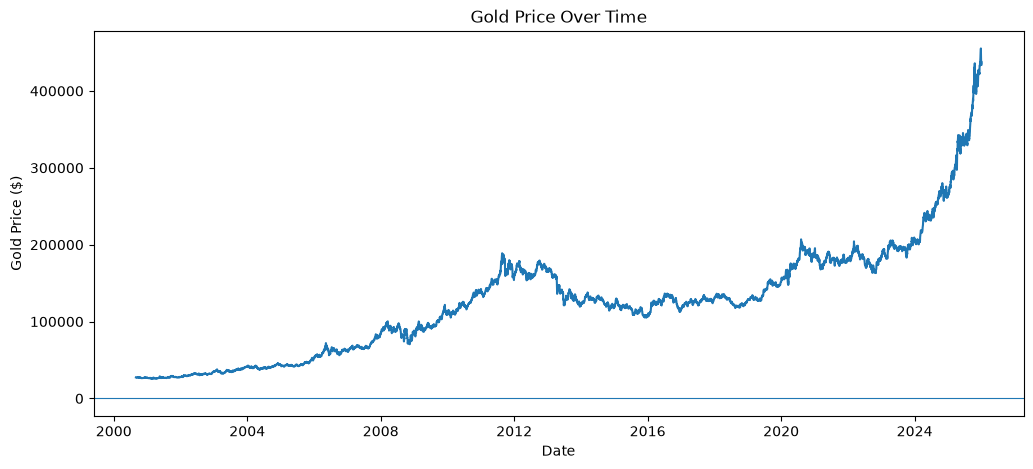

In [73]:
plt.figure(figsize=(12, 5))

plt.plot(gold_price.index, gold_price * 100)

plt.title("Gold Price Over Time")
plt.xlabel("Date")
plt.ylabel("Gold Price ($)")
plt.axhline(0, linewidth=0.8)

plt.show()

# Evolution du coût de l'or par rapport au S&P 500

In [252]:
tickers = ["^SP500TR"]
sp500 = yf.download(tickers,  start="2000-01-01", end="2026-01-01",interval="1d", auto_adjust=True)

[*********************100%***********************]  1 of 1 completed


In [253]:
sp500 = sp500["Close"]

In [254]:
sp500

Ticker,^SP500TR
Date,
2000-01-03,2002.109985
2000-01-04,1925.410034
2000-01-05,1929.280029
2000-01-06,1931.510010
2000-01-07,1983.829956
...,...
2025-12-24,15409.700195
2025-12-26,15406.480469
2025-12-29,15353.160156


In [255]:
gold_normalized = gold_price / gold_price.iloc[0]

sp500_normalized = sp500 / sp500.iloc[0]

In [256]:
gold_normalized

Ticker,GC=F
Date,
2000-08-30,1.000000
2000-08-31,1.016064
2000-09-01,1.011318
2000-09-05,1.006937
2000-09-06,1.001095
...,...
2025-12-24,16.439576
2025-12-26,16.621761
2025-12-29,15.858343


In [257]:
sp500_normalized

Ticker,^SP500TR
Date,
2000-01-03,1.000000
2000-01-04,0.961690
2000-01-05,0.963623
2000-01-06,0.964737
2000-01-07,0.990870
...,...
2025-12-24,7.696730
2025-12-26,7.695122
2025-12-29,7.668490


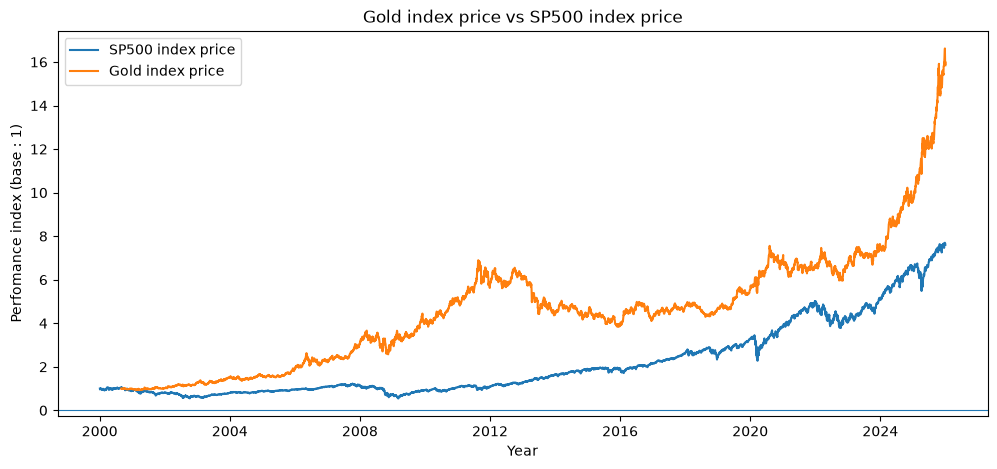

In [259]:
plt.figure(figsize=(12, 5))

plt.plot(
    sp500_normalized.index,
    sp500_normalized["^SP500TR"],
    label="SP500 index price"
)

plt.plot(
    gold_normalized.index,
    gold_normalized["GC=F"],
    label="Gold index price"
)

plt.axhline(0, linewidth=0.8)

plt.title("Gold index price vs SP500 index price")
plt.xlabel("Year")
plt.ylabel("Perfomance index (base : 1)")
plt.legend()

# plt.xticks(gold_inflation.index, rotation=45)

plt.show()

L’indice normalisé montre que l’or surperforme le S&P 500 sur l’ensemble de la période depuis 2000.

Ainsi, pour 1 dollar investi en or en 2000, vous auriez obtenu environ 16 dollars à la fin de 2025. En revanche, pour 1 dollar investi dans le S&P 500, vous auriez obtenu environ 8 dollars à la fin de 2025.


# Evolution de la valeur d'un investissement au cours du temps

In [212]:
daily_returns = gold_price / gold_price.shift(1) - 1

In [183]:
daily_returns

Ticker,GC=F
Date,
2000-08-30,NaN
2000-08-31,0.016064
2000-09-01,-0.004671
2000-09-05,-0.004332
2000-09-06,-0.005801
...,...
2025-12-24,-0.000644
2025-12-26,0.011082
2025-12-29,-0.045929


In [184]:
daily_cleaned = daily_returns.dropna()

In [185]:
# Monthly return
monthly_return = (1 + daily_cleaned).resample("ME").prod() - 1

# Annual return
annual_return = (1 + daily_cleaned).resample("YE").prod() - 1
annual_return.index = pd.to_datetime(annual_return.index)
annual_return.index = annual_return.index.year

In [186]:
monthly_return

Ticker,GC=F
Date,
2000-08-31,0.016064
2000-09-30,-0.016888
2000-10-31,-0.031798
2000-11-30,0.019630
2000-12-31,0.007034
...,...
2025-08-31,0.067685
2025-09-30,0.101561
2025-10-31,0.031834


# Monthly Gold return

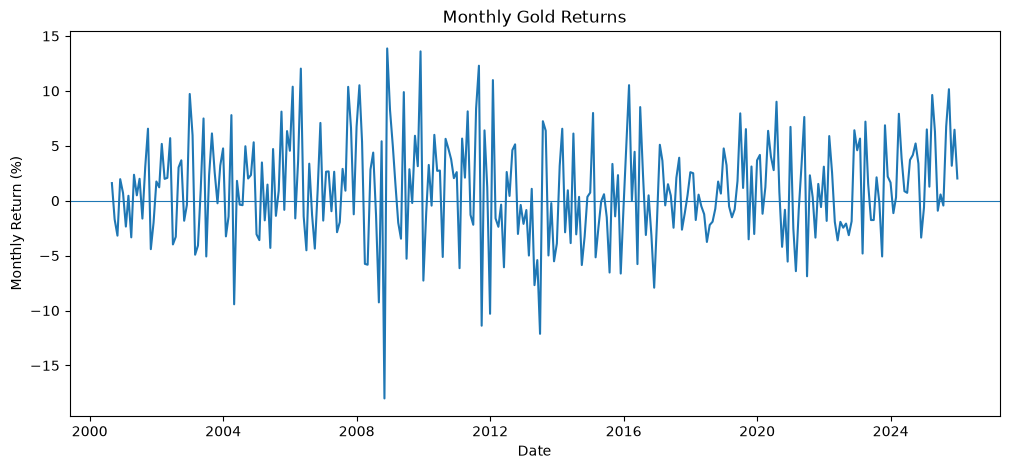

In [187]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_return.index, monthly_return * 100)

plt.title("Monthly Gold Returns")
plt.xlabel("Date")
plt.ylabel("Monthly Return (%)")
plt.axhline(0, linewidth=0.8)

plt.show()

In [188]:
average_monthly_return = monthly_return.mean()

In [189]:
average_monthly_return

Ticker
GC=F    0.010177
dtype: float64

In [190]:
annual_return_cleaned = annual_return["GC=F"]

In [191]:
annual_return_cleaned

Date
2000   -0.006937
2001    0.024632
2002    0.247219
2003    0.195915
2004    0.052442
2005    0.181943
2006    0.228389
2007    0.314389
2008    0.058330
2009    0.239475
2010    0.297571
2011    0.101823
2012    0.069613
2013   -0.282362
2014   -0.014976
2015   -0.104401
2016    0.084599
2017    0.135913
2018   -0.021435
2019    0.188688
2020    0.247187
2021   -0.035090
2022   -0.001312
2023    0.134487
2024    0.274737
2025    0.643733
Name: GC=F, dtype: float64

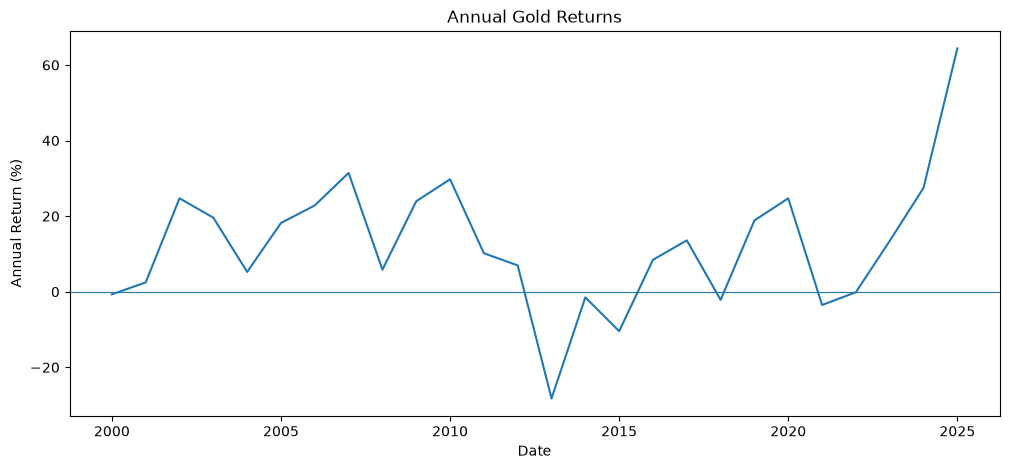

In [192]:
plt.figure(figsize=(12, 5))

plt.plot(annual_return.index, annual_return * 100)

plt.title("Annual Gold Returns")
plt.xlabel("Date")
plt.ylabel("Annual Return (%)")
plt.axhline(0, linewidth=0.8)

plt.show()

# USA Inflation

In [193]:
data_cpi = pd.read_csv("CPIAUCSL.csv")

In [194]:
data_cpi 

,observation_date,CPIAUCSL
0,1947-01-01,21.480
1,1947-02-01,21.620
2,1947-03-01,22.000
3,1947-04-01,22.000
4,1947-05-01,21.950
...,...,...
951,2026-04-01,332.407
952,2026-05-01,333.979
953,2026-06-01,332.568
954,2026-07-01,332.813


In [195]:
data_cpi['observation_date'] = pd.to_datetime(data_cpi['observation_date'])

In [196]:
data_cpi = data_cpi.set_index('observation_date')

In [197]:
data_cpi 

,CPIAUCSL
observation_date,
1947-01-01,21.480
1947-02-01,21.620
1947-03-01,22.000
1947-04-01,22.000
1947-05-01,21.950
...,...
2026-04-01,332.407
2026-05-01,333.979
2026-06-01,332.568


In [198]:
# Monthly average CPI
cpi_monthly = data_cpi["CPIAUCSL"].resample("ME").mean()

In [199]:
# Monthly inflation rate
monthly_inflation = cpi_monthly.pct_change() * 100

In [200]:
monthly_inflation

observation_date
1947-01-31         NaN
1947-02-28    0.651769
1947-03-31    1.757632
1947-04-30    0.000000
1947-05-31   -0.227273
                ...   
2026-04-30    0.640038
2026-05-31    0.472914
2026-06-30   -0.422482
2026-07-31    0.073669
2026-08-31    0.396018
Freq: ME, Name: CPIAUCSL, Length: 956, dtype: float64

In [201]:
# Annual average CPI
cpi_annual = data_cpi["CPIAUCSL"].resample("YE").mean()

# Annual inflation rate
annual_inflation = cpi_annual.pct_change() * 100

In [202]:
annual_inflation

observation_date
1947-12-31         NaN
1948-12-31    7.672214
1949-12-31   -0.980800
1950-12-31    1.064016
1951-12-31    7.941126
                ...   
2022-12-31    7.990821
2023-12-31    4.126963
2024-12-31    2.952110
2025-12-31    2.634297
2026-12-31    2.894121
Freq: YE-DEC, Name: CPIAUCSL, Length: 80, dtype: float64

In [203]:
annual_inflation.dropna()

observation_date
1948-12-31    7.672214
1949-12-31   -0.980800
1950-12-31    1.064016
1951-12-31    7.941126
1952-12-31    2.284394
                ...   
2022-12-31    7.990821
2023-12-31    4.126963
2024-12-31    2.952110
2025-12-31    2.634297
2026-12-31    2.894121
Freq: YE-DEC, Name: CPIAUCSL, Length: 79, dtype: float64

In [204]:
annual_inflation.index = pd.to_datetime(annual_inflation.index)
annual_inflation.index = annual_inflation.index.year

In [205]:
annual_inflation_2001 = annual_inflation[
    (annual_inflation.index >= 2000) &
    (annual_inflation.index < 2026)
]

In [206]:
annual_inflation_2001

observation_date
2000    3.366683
2001    2.816629
2002    1.595670
2003    2.297999
2004    2.667572
2005    3.365830
2006    3.222089
2007    2.870550
2008    3.814953
2009   -0.320358
2010    1.636570
2011    3.139652
2012    2.073191
2013    1.465972
2014    1.615463
2015    0.121137
2016    1.267361
2017    2.131445
2018    2.439000
2019    1.813259
2020    1.252937
2021    4.681243
2022    7.990821
2023    4.126963
2024    2.952110
2025    2.634297
Name: CPIAUCSL, dtype: float64

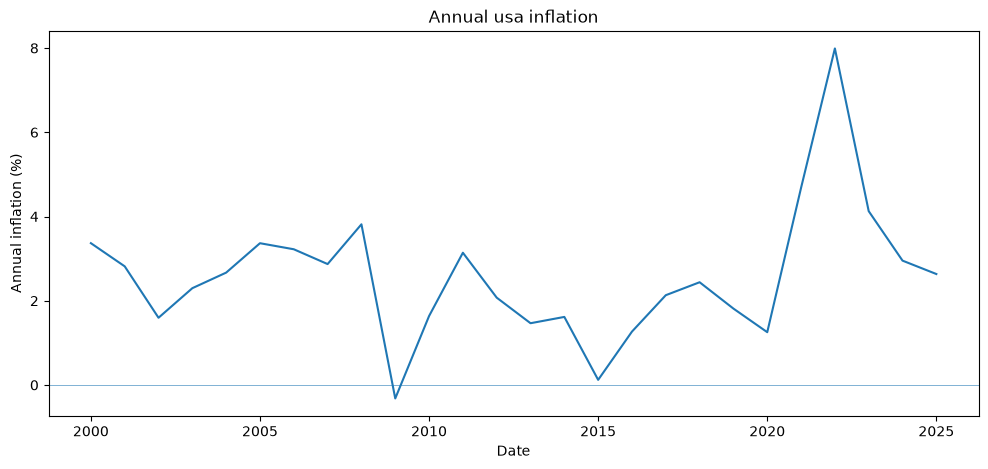

In [207]:
plt.figure(figsize=(12, 5))

plt.plot(annual_inflation_2001.index, annual_inflation_2001)

# plt.xticks(annual_inflation_2001.index)
plt.title("Annual usa inflation")
plt.xlabel("Date")
plt.ylabel("Annual inflation (%)")
plt.axhline(0, linewidth=0.4)

plt.show()

In [208]:
annual_inflation_2001 = annual_inflation_2001.rename("Inflation")
annual_return_cleaned = annual_return_cleaned.rename("Gold Return")*100

In [209]:
gold_inflation = pd.concat(
    [annual_return_cleaned, annual_inflation_2001],
    axis=1
)

In [210]:
gold_inflation

,Gold Return,Inflation
2000,-0.693682,3.366683
2001,2.463240,2.816629
2002,24.721920,1.595670
2003,19.591486,2.297999
2004,5.244163,2.667572
2005,18.194280,3.365830
2006,22.838917,3.222089
2007,31.438918,2.870550
2008,5.833028,3.814953
2009,23.947485,-0.320358


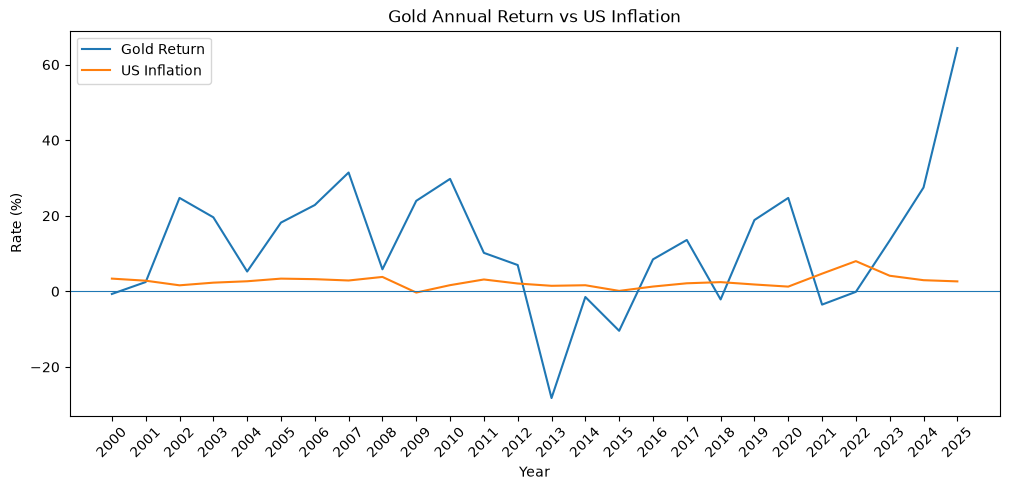

In [211]:
plt.figure(figsize=(12, 5))

plt.plot(
    gold_inflation.index,
    gold_inflation["Gold Return"],
    label="Gold Return"
)

plt.plot(
    gold_inflation.index,
    gold_inflation["Inflation"],
    label="US Inflation"
)

plt.axhline(0, linewidth=0.8)

plt.title("Gold Annual Return vs US Inflation")
plt.xlabel("Year")
plt.ylabel("Rate (%)")
plt.legend()

plt.xticks(gold_inflation.index, rotation=45)

plt.show()

# Rendement réel de l'or

In [179]:
# Calculate real Gold Return
gold_inflation["Real Gold Return (%)"] = (
    (1 + gold_inflation["Gold Return"] / 100)
    / (1 + gold_inflation["Inflation"] / 100)
    - 1
) * 100

In [180]:
gold_inflation

,Gold Return,Inflation,Real Gold Return (%)
2000,-0.693682,3.366683,-3.928118
2001,2.463240,2.816629,-0.343708
2002,24.721920,1.595670,22.763028
2003,19.591486,2.297999,16.905010
2004,5.244163,2.667572,2.509644
2005,18.194280,3.365830,14.345602
2006,22.838917,3.222089,19.004486
2007,31.438918,2.870550,27.771182
2008,5.833028,3.814953,1.943915
2009,23.947485,-0.320358,24.345837


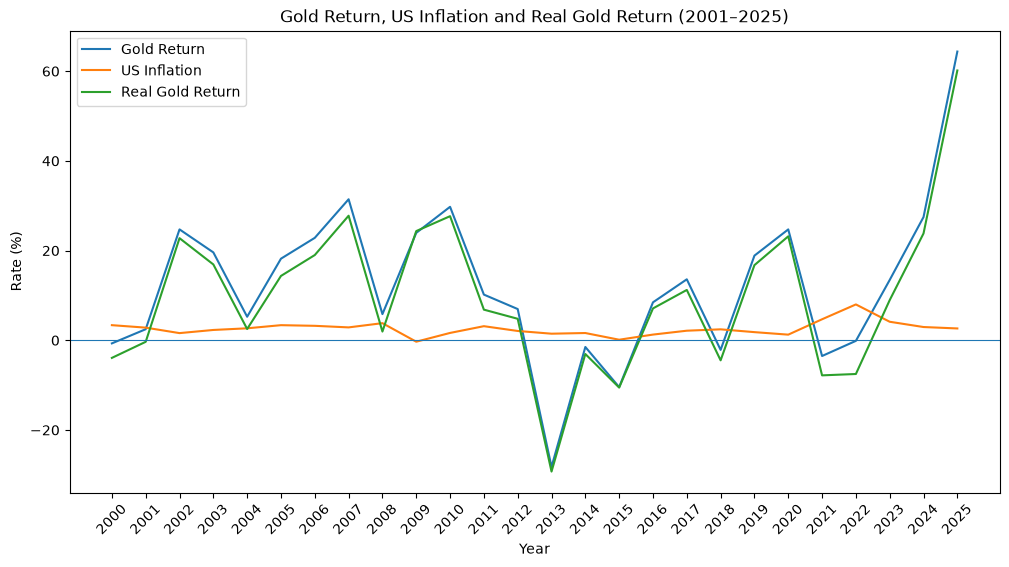

In [181]:
plt.figure(figsize=(12, 6))

plt.plot(
    gold_inflation.index,
    gold_inflation["Gold Return"],
    label="Gold Return"
)

plt.plot(
    gold_inflation.index,
    gold_inflation["Inflation"],
    label="US Inflation"
)

plt.plot(
    gold_inflation.index,
    gold_inflation["Real Gold Return (%)"],
    label="Real Gold Return"
)

plt.axhline(0, linewidth=0.8)

plt.title("Gold Return, US Inflation and Real Gold Return (2001–2025)")
plt.xlabel("Year")
plt.ylabel("Rate (%)")
plt.legend()

plt.xticks(annual_inflation_2001.index, rotation=45)

plt.show()